# NYC Taxi Trip Duration Prediction

**Author:** Mayur More · **Context:** Academic supervised-regression project.

The workflow predicts `trip_duration` in seconds using trip coordinates, pickup time, vendor/passenger information and engineered features. The labelled Kaggle `train.csv` is the modelling pool; competition `test.csv` has no target and is not used for internal evaluation.

**Evidence status:** this notebook contains source code and narrative only, with no saved execution outputs. Numeric performance values in the original conclusion are reported claims, not independently reproduced results. Implementation and evaluation limits are documented in [EVIDENCE.md](docs/EVIDENCE.md).

## Dataset and setup

Download from [Kaggle: New York City Taxi Trip Duration](https://www.kaggle.com/competitions/nyc-taxi-trip-duration/data). Access may require signing in and accepting competition rules.

Place `train.csv` beside this notebook, or use `train.zip` containing `train.csv`, or `nyc-taxi-trip-duration.zip` containing `train.zip`. Start Jupyter from the repository root. See [data documentation](docs/DATA.md) for input structure and source attribution. Raw data and private download links are not distributed.

## 1. Problem definition

Predict trip duration in seconds from trip endpoints and information known at pickup, under a historical academic regression setup. Accurate duration estimates can be useful for planning, but this project does not establish dispatch, routing, customer-service or production benefits. The endpoint coordinates are treated as available input; the study does not validate an operational deployment.

## 1A. Workflow

Load labelled data → derive distance, time and airport features → filter coordinates/durations → fit location clusters on the full filtered pool → random 70/15/15 split → training exploration → model preprocessing and comparison → retained parameter configurations → test error analysis.

The ordering above reflects the current code. Location clustering is fitted before the split; final model selection has a name-matching limitation. See [methods](docs/METHODS.md).

## 2. Imports, Settings, and Data Loading

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.cluster import MiniBatchKMeans
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import zipfile
import io

RS = 42     #Random state

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
if Path("train.csv").is_file():
    print("Loading train.csv")
    main_df = pd.read_csv("train.csv")

elif Path("train.zip").is_file() and zipfile.is_zipfile("train.zip"):
    print("Loading train.zip -> train.csv")
    with zipfile.ZipFile("train.zip") as z:
        main_df = pd.read_csv(z.open("train.csv"))

elif Path("nyc-taxi-trip-duration.zip").is_file() and zipfile.is_zipfile("nyc-taxi-trip-duration.zip"):
    print("Loading nyc-taxi-trip-duration.zip -> train.zip -> train.csv")
    with zipfile.ZipFile("nyc-taxi-trip-duration.zip") as main_zip:
        train_zip_bytes = main_zip.read("train.zip")

    with zipfile.ZipFile(io.BytesIO(train_zip_bytes)) as train_zip:
        main_df = pd.read_csv(train_zip.open("train.csv"))

else:
    raise FileNotFoundError(
        "Place a valid train.csv, train.zip, or nyc-taxi-trip-duration.zip in this notebook folder."
    )

print("Train dataset shape:", main_df.shape)
display(main_df.head())

Loading nyc-taxi-trip-duration.zip -> train.zip -> train.csv
Train dataset shape: (1458644, 11)


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


## 3. First Data Check

In [3]:
# Chek raw dataset structure, missing values, duplicate rows, and numeric summaries before cleaning.
main_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  object 
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  object 
 3   dropoff_datetime    1458644 non-null  object 
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  object 
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), object(4)
memory usage: 122.4+ MB


In [4]:
print("\nDuplicate rows:", main_df.duplicated().sum())
print("\nMissing values:")
display(main_df.isnull().sum())


Duplicate rows: 0

Missing values:


id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

The code checks missing values and duplicate rows. This notebook has no saved outputs for those checks. Independent input-summary results are documented separately; absence of saved errors is not evidence of a successful run.

In [5]:
target_corr = (main_df.corr(numeric_only=True)["trip_duration"].drop("trip_duration").sort_values(key=abs, ascending=False))
display(target_corr)

pickup_latitude     -0.029204
pickup_longitude     0.026542
dropoff_latitude    -0.020677
vendor_id            0.020304
dropoff_longitude    0.014678
passenger_count      0.008471
Name: trip_duration, dtype: float64

The code inspects numeric linear correlations with the target. Weak linear correlation alone does not prove that a feature is uninformative or that a specific engineered feature improves predictions.

## 4. Feature Engineering

`Convert raw datetime (object) strings into datetime objects so time-based features can be extracted.`

In [6]:
main_df["pickup_datetime"] = pd.to_datetime(main_df["pickup_datetime"])
main_df["dropoff_datetime"] = pd.to_datetime(main_df["dropoff_datetime"])

Haversine distance estimates great-circle separation between pickup and dropoff coordinates. It is a straight-line approximation, not a measured driven route.

In [7]:
def hav_dist(lat1, lon1, lat2, lon2):
    R = 6371
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    diff_lat = lat2 - lat1
    diff_lon = lon2 - lon1
    a = (np.sin(diff_lat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(diff_lon / 2) ** 2)
    haversine = R * 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return haversine

Bearing represents travel direction between the recorded endpoints, in degrees. It is not a measured vehicle heading throughout the trip.

In [8]:
def bear_dir(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lat2 = np.radians(lat2)
    diff_lon = np.radians(lon2 - lon1)
    x = np.sin(diff_lon) * np.cos(lat2)
    y = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(diff_lon)
    bearing = np.degrees(np.arctan2(x, y))
    bearing_angle = (bearing + 360) % 360
    return bearing_angle

In [9]:
main_df["pickup_datetime"] = pd.to_datetime(main_df["pickup_datetime"])
main_df["pickup_month"] = main_df["pickup_datetime"].dt.month
main_df["pickup_dayofweek"] = main_df["pickup_datetime"].dt.dayofweek
main_df["pickup_hour"] = main_df["pickup_datetime"].dt.hour
main_df["pickup_min"] = main_df["pickup_datetime"].dt.minute
main_df["is_weekend"] = main_df["pickup_dayofweek"].isin([5, 6]).astype(int)
main_df["is_rush_hour"] = main_df["pickup_hour"].isin([8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]).astype(int)

In [10]:
main_df["latitude_difference"] = main_df["dropoff_latitude"] - main_df["pickup_latitude"]
main_df["longitude_difference"] = main_df["dropoff_longitude"] - main_df["pickup_longitude"]
main_df["haversine_dist"] = hav_dist(main_df["pickup_latitude"],main_df["pickup_longitude"],main_df["dropoff_latitude"],main_df["dropoff_longitude"],)

main_df["log_haversine_dist"] = np.log1p(main_df["haversine_dist"])

A Manhattan-style approximation adds north–south and east–west endpoint separation. The calculation uses roughly 111 km per latitude degree and a latitude adjustment for longitude. It is not a routed street-network distance.

In [11]:
lat_distance_km = main_df["latitude_difference"].abs() * 111
lon_distance_km = ( main_df["longitude_difference"].abs() * 111 * np.cos(np.radians((main_df["pickup_latitude"] + main_df["dropoff_latitude"]) / 2)))
main_df["manhattan_dist"] = lat_distance_km + lon_distance_km

In [12]:
main_df["bearing"] = bear_dir(main_df["pickup_latitude"],main_df["pickup_longitude"], main_df["dropoff_latitude"],main_df["dropoff_longitude"])

`Bearing and cyclic time features help represent direction, hour, and day-of-week patterns. So the model knows its a cylic data`

In [13]:
main_df["bearing_sin"] = np.sin(2 * np.pi * main_df["bearing"] / 360)
main_df["bearing_cos"] = np.cos(2 * np.pi * main_df["bearing"] / 360)
main_df["pickup_hour_sin"] = np.sin(2 * np.pi * main_df["pickup_hour"] / 24)
main_df["pickup_hour_cos"] = np.cos(2 * np.pi * main_df["pickup_hour"] / 24)
main_df["pickup_dayofweek_sin"] = np.sin(2 * np.pi * main_df["pickup_dayofweek"] / 7)
main_df["pickup_dayofweek_cos"] = np.cos(2 * np.pi * main_df["pickup_dayofweek"] / 7)

`Airport indicators identify trips near JFK, LGA, or EWR. `

In [14]:
def near_airport(lat, lon, airport_lat, airport_lon, radius_km=4):
    distance = hav_dist(lat, lon, airport_lat, airport_lon)
    return (distance <= radius_km).astype(int)


airports = {
    "jfk": (40.6413, -73.7781),
    "lga": (40.7769, -73.8740),
    "ewr": (40.6895, -74.1745),
}

air_cols = []
for name, (lat, lon) in airports.items():
    for point in ["pickup", "dropoff"]:
        col = f"{point}_near_{name}"
        air_cols.append(col)
        main_df[col] = near_airport(main_df[f"{point}_latitude"], main_df[f"{point}_longitude"], lat, lon)

main_df["is_airport_trip"] = main_df[air_cols].any(axis=1).astype(int)

In [15]:
main_df["trip_duration_min"] = main_df["trip_duration"] / 60
display(main_df.sample(5))

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,pickup_month,pickup_dayofweek,pickup_hour,pickup_min,is_weekend,is_rush_hour,latitude_difference,longitude_difference,haversine_dist,log_haversine_dist,manhattan_dist,bearing,bearing_sin,bearing_cos,pickup_hour_sin,pickup_hour_cos,pickup_dayofweek_sin,pickup_dayofweek_cos,pickup_near_jfk,dropoff_near_jfk,pickup_near_lga,dropoff_near_lga,pickup_near_ewr,dropoff_near_ewr,is_airport_trip,trip_duration_min
1261401,id0665452,1,2016-04-26 22:01:07,2016-04-26 22:09:33,1,-73.993340,40.727180,-74.003639,40.745865,N,506,4,1,22,1,0,0,0.018684,-0.010300,2.251561,1.179135,2.940240,337.333611,-0.385365,0.922764,-0.500000,0.866025,0.781831,0.623490,0,0,0,0,0,0,0,8.433333
90789,id0330142,2,2016-05-23 14:03:01,2016-05-23 14:07:30,1,-73.966393,40.789612,-73.974373,40.783192,N,269,5,0,14,3,0,1,-0.006420,-0.007980,0.980332,0.683264,1.383333,223.266144,-0.685388,-0.728178,-0.500000,-0.866025,0.000000,1.000000,0,0,0,0,0,0,0,4.483333
571235,id0906532,2,2016-03-14 17:24:07,2016-03-14 17:37:04,1,-73.968552,40.761608,-73.982857,40.750542,N,777,3,0,17,24,0,1,-0.011066,-0.014305,1.722216,1.001446,2.431178,224.402049,-0.699689,-0.714448,-0.965926,-0.258819,0.000000,1.000000,0,0,0,0,0,0,0,12.950000
624129,id1108371,2,2016-05-22 16:20:31,2016-05-22 16:30:01,1,-73.995453,40.744251,-73.996025,40.726292,N,570,5,6,16,20,1,1,-0.017960,-0.000572,1.997598,1.097811,2.041642,181.383145,-0.024138,-0.999709,-0.866025,-0.500000,-0.781831,0.623490,0,0,0,0,0,0,0,9.500000
831146,id1040700,1,2016-06-08 13:36:53,2016-06-08 13:49:20,1,-73.993027,40.759907,-73.997520,40.742329,N,747,6,2,13,36,0,1,-0.017578,-0.004494,1.990915,1.095579,2.329041,190.961828,-0.190155,-0.981754,-0.258819,-0.965926,0.974928,-0.222521,0,0,0,0,0,0,0,12.450000


## 5. Feature exclusions

The code removes `id` and `dropoff_datetime`. The latter is post-trip information related directly to duration. The derived `trip_duration_min` is used for exploration and excluded from the final model feature lists. These exclusions do not eliminate the separate pre-split clustering limitation.

In [16]:
mdf = main_df.drop(columns=["id", "dropoff_datetime"])
print("Dataset after removing leakage columns:", mdf.shape)
print(mdf.columns.tolist())

Dataset after removing leakage columns: (1458644, 35)
['vendor_id', 'pickup_datetime', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag', 'trip_duration', 'pickup_month', 'pickup_dayofweek', 'pickup_hour', 'pickup_min', 'is_weekend', 'is_rush_hour', 'latitude_difference', 'longitude_difference', 'haversine_dist', 'log_haversine_dist', 'manhattan_dist', 'bearing', 'bearing_sin', 'bearing_cos', 'pickup_hour_sin', 'pickup_hour_cos', 'pickup_dayofweek_sin', 'pickup_dayofweek_cos', 'pickup_near_jfk', 'dropoff_near_jfk', 'pickup_near_lga', 'dropoff_near_lga', 'pickup_near_ewr', 'dropoff_near_ewr', 'is_airport_trip', 'trip_duration_min']


## 6. Filtering and distribution checks

The code keeps pickup/dropoff coordinates within a broad bounding box and durations from 20 seconds through four hours. These are modelling scope choices, not independent proof that every excluded trip is an erroneous record. Resulting evaluation concerns the filtered population.

In [17]:
print("Rows before cleaning:", len(mdf))
display(mdf["trip_duration_min"].describe())
print("Trip duration skewness:", mdf["trip_duration_min"].skew())
print("Log trip duration skewness:", np.log1p(mdf["trip_duration"]).skew())

Rows before cleaning: 1458644


count    1.458644e+06
mean     1.599154e+01
std      8.729053e+01
min      1.666667e-02
25%      6.616667e+00
50%      1.103333e+01
75%      1.791667e+01
max      5.877137e+04
Name: trip_duration_min, dtype: float64

Trip duration skewness: 343.16394359173586
Log trip duration skewness: -0.290160923725991


Raw and log-transformed target skewness are computed for inspection. There is no universal accepted skewness interval that establishes validity of regression data.

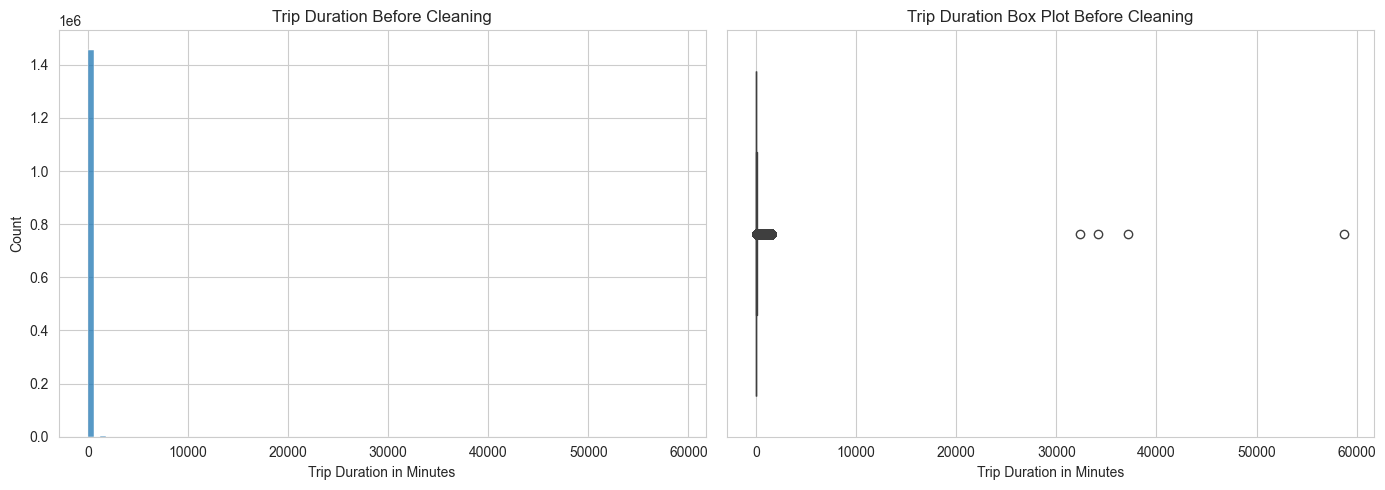

In [18]:
# Visualize the raw target distribution and GPS coordinates to understand outliers before applying filters.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(mdf["trip_duration_min"], bins=100, ax=axes[0])
axes[0].set_title("Trip Duration Before Cleaning")
axes[0].set_xlabel("Trip Duration in Minutes")
sns.boxplot(x=mdf["trip_duration_min"], ax=axes[1])
axes[1].set_title("Trip Duration Box Plot Before Cleaning")
axes[1].set_xlabel("Trip Duration in Minutes")
plt.tight_layout()
plt.show()

The histogram and box plot are intended to show the duration distribution before filtering. Long trips can reflect multiple causes; this code does not establish meter or driver errors.

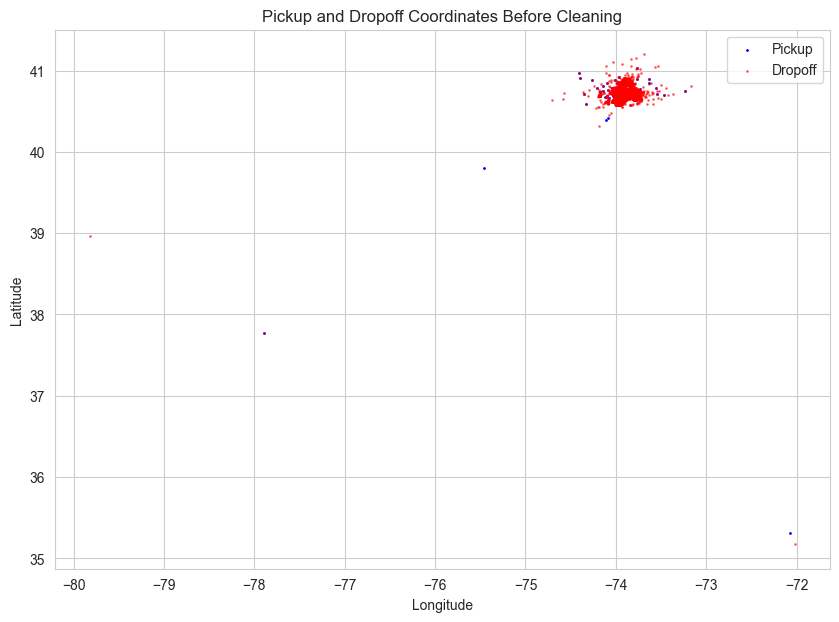

In [19]:
geo_raw = mdf.sample(min(100000, len(mdf)), random_state=RS) # for fast loading we take small sample set
 
plt.figure(figsize=(10, 7))

plt.scatter(geo_raw["pickup_longitude"],geo_raw["pickup_latitude"], s=1,alpha=1,color="blue",label="Pickup")

plt.scatter(geo_raw["dropoff_longitude"],geo_raw["dropoff_latitude"], s=1,alpha=0.5,color="red",label="Dropoff")

plt.title("Pickup and Dropoff Coordinates Before Cleaning")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()

The coordinate plot is intended to show the raw spatial extent. Coordinates outside the selected bounding box are excluded by the modelling rule; their causes are not established.

In [20]:
n_before = len(mdf)  # length of data frame before cleaning

# Keep only trips whose pickup and dropoff GPS points fall within a broad NYC GPS bounding box.

box = (mdf["pickup_longitude"].between(-74.5, -73.25) & mdf["pickup_latitude"].between(40.4, 41.2)
           & mdf["dropoff_longitude"].between(-74.5, -73.25) & mdf["dropoff_latitude"].between(40.4, 41.2))

In [21]:
# Keep real trip durations: at least 20 seconds and at most 4 hours.

duration_mask = mdf["trip_duration"].between(20, 4 * 60 * 60)

In [22]:
gps_out = (~box).sum()
dur_out = (~duration_mask).sum()
dfc = mdf[box & duration_mask].copy()
n_after = len(dfc)

In [23]:
out_sum = pd.DataFrame({
    "Outlier Type": ["GPS outside NYC bounding box","Duration below 20 sec or above 4 hours","Total removed after combined filters",],
    "Rows": [gps_out, dur_out, n_before - n_after],
    "Percentage": [gps_out / n_before * 100,dur_out / n_before * 100,(n_before - n_after) / n_before * 100,], })

print("Rows before cleaning:", n_before)
print("Rows after cleaning:", n_after)
display(out_sum)


Rows before cleaning: 1458644
Rows after cleaning: 1452939


,Outlier Type,Rows,Percentage
0,GPS outside NYC bounding box,115,0.007884
1,Duration below 20 sec or above 4 hours,5598,0.383781
2,Total removed after combined filters,5705,0.391117


In [24]:
print("Trip duration skewness:", dfc["trip_duration_min"].skew())
print("Log trip duration skewness:", np.log1p(dfc["trip_duration"]).skew())

Trip duration skewness: 2.4072621760695694
Log trip duration skewness: -0.27607832094834445


The code computes skewness and visualizes duration after filtering. Saved plots and numerical outputs are absent from this notebook.

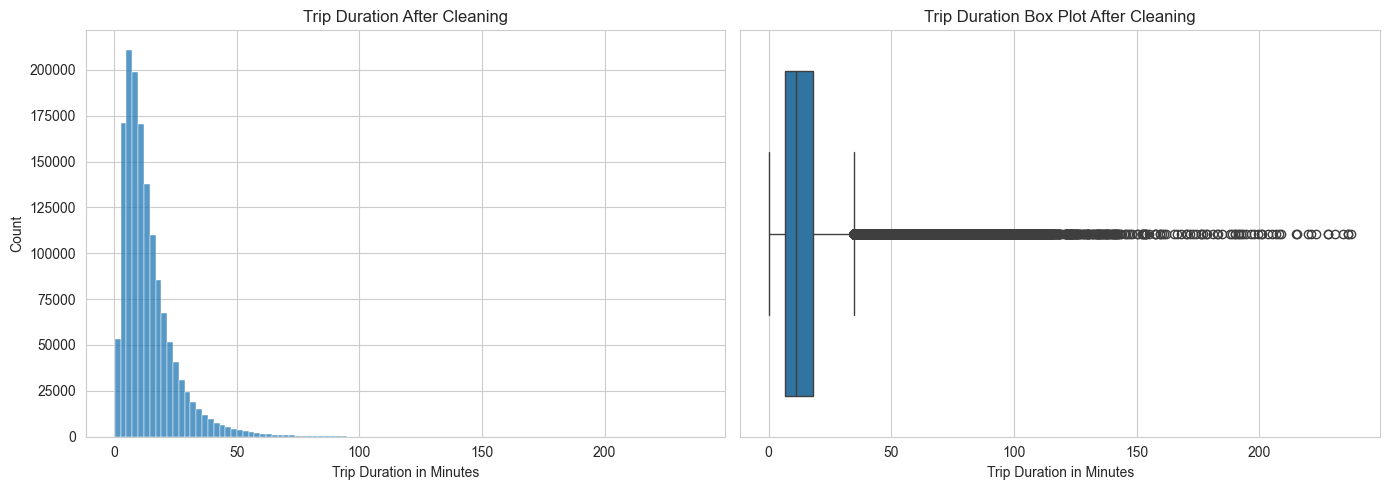

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(dfc["trip_duration_min"], bins=100, ax=axes[0])
axes[0].set_title("Trip Duration After Cleaning")
axes[0].set_xlabel("Trip Duration in Minutes")
sns.boxplot(x=dfc["trip_duration_min"], ax=axes[1])
axes[1].set_title("Trip Duration Box Plot After Cleaning")
axes[1].set_xlabel("Trip Duration in Minutes")
plt.tight_layout()
plt.show()

This cell defines the post-filter duration histogram and box plot. No rendered plot is saved in this copy.

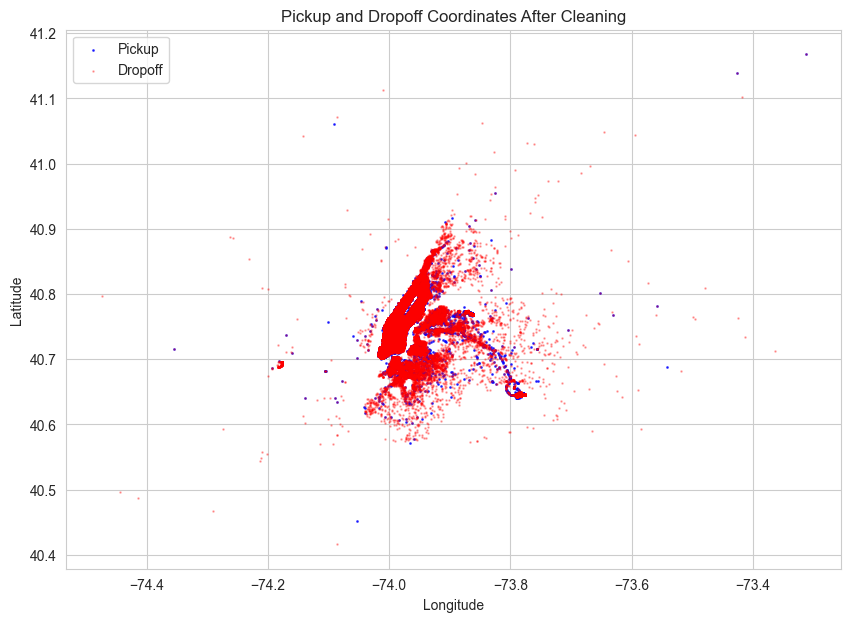

In [26]:
geo_clean = dfc.sample(min(100000, len(dfc)), random_state=RS) # for fast loading we take small sample set
 
plt.figure(figsize=(10, 7))
plt.scatter(geo_clean["pickup_longitude"],geo_clean["pickup_latitude"], s=1,alpha=0.7,color="blue",label="Pickup")
plt.scatter(geo_clean["dropoff_longitude"],geo_clean["dropoff_latitude"], s=0.7,alpha=0.3,color="red",label="Dropoff")
plt.title("Pickup and Dropoff Coordinates After Cleaning")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()

The post-filter coordinate plot uses a seeded sample of up to 100,000 rows inside the specified bounding box.

## 6.1 Location clusters

MiniBatchKMeans creates 25 spatial zones from pooled pickup/dropoff coordinates. The code fits clusters on all filtered rows **before** the training/validation/test split. It does not use target values, but it learns from validation/test coordinates; the complete workflow is therefore not training-only preprocessing.

In [27]:
N_LOCATION_CLUSTERS = 25
NYC_LAT, NYC_LON = 40.7128, -74.0060

def xy_km(lat, lon):
    x = (lon - NYC_LON) * 111 * np.cos(np.radians(NYC_LAT))
    y = (lat - NYC_LAT) * 111
    return np.c_[x, y]

p_xy = xy_km(dfc["pickup_latitude"], dfc["pickup_longitude"])
d_xy = xy_km(dfc["dropoff_latitude"], dfc["dropoff_longitude"])

kmeans = MiniBatchKMeans(
    n_clusters=N_LOCATION_CLUSTERS, random_state=RS, batch_size=4096, n_init=10
).fit(np.vstack([p_xy, d_xy]))

dfc["pickup_cluster"] = kmeans.predict(p_xy)
dfc["dropoff_cluster"] = kmeans.predict(d_xy)
dfc["same_cluster"] = (dfc["pickup_cluster"] == dfc["dropoff_cluster"]).astype(int)

display(dfc[["pickup_cluster", "dropoff_cluster", "same_cluster"]].head())

,pickup_cluster,dropoff_cluster,same_cluster
0,8,7,0
1,11,9,0
2,10,15,0
3,15,15,1
4,2,2,1


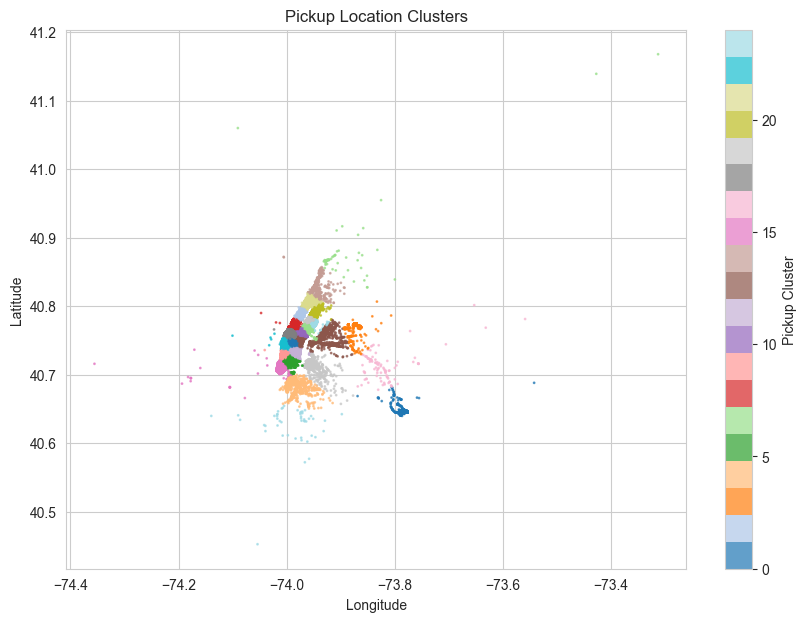

,pickup_cluster,trips,mean_duration_sec,median_duration_sec,mean_distance_km
0,0,154447,776.473735,639.0,2.733958
10,10,140671,777.206631,640.0,2.788197
17,17,132685,808.000008,654.0,3.104735
13,13,108898,770.947272,649.0,2.849305
11,11,107166,762.174701,637.0,2.813414


In [28]:
cs = dfc.sample(min(100000, len(dfc)), random_state=RS)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    cs["pickup_longitude"],
    cs["pickup_latitude"],
    c=cs["pickup_cluster"],
    cmap="tab20",
    s=1,
    alpha=0.7,
)
plt.title("Pickup Location Clusters")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.colorbar(scatter, label="Pickup Cluster")
plt.show()

cl_sum = (
    dfc
    .groupby("pickup_cluster")
    .agg(
        trips=("trip_duration", "count"),
        mean_duration_sec=("trip_duration", "mean"),
        median_duration_sec=("trip_duration", "median"),
        mean_distance_km=("haversine_dist", "mean"),
    )
    .reset_index()
    .sort_values("trips", ascending=False)
)

display(cl_sum.head(5))


## 7. Train, Validation, and Test Split

In [29]:
# Training 70%, Validation 15% and Testing 15%

trn, temp_data = train_test_split(dfc,test_size=0.30,random_state=RS)

val, tst = train_test_split(temp_data,test_size=0.50,random_state=RS)

print("Training data:", trn.shape)
print("Validation data:", val.shape)
print("Testing data:", tst.shape)


Training data: (1017057, 38)
Validation data: (217941, 38)
Testing data: (217941, 38)


## 8. Exploration on training data

These EDA cells use the training partition. Earlier quality checks, filters and location clustering use the full modelling pool. The training-only EDA does not make the entire preceding workflow training-only.

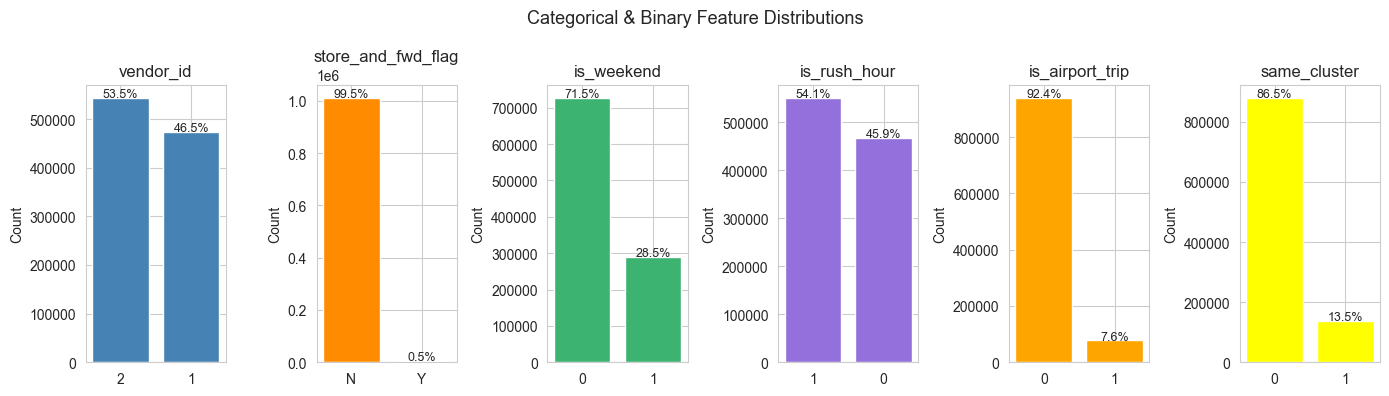

In [30]:
cat_bin = ["vendor_id", "store_and_fwd_flag","is_weekend","is_rush_hour","is_airport_trip","same_cluster"]
cat_bin = [c for c in cat_bin if c in trn.columns]

fig, axes = plt.subplots(1, len(cat_bin), figsize=(14, 4))
if len(cat_bin) == 1:
    axes = [axes]

colors = ['steelblue', 'darkorange', 'mediumseagreen', 'mediumpurple','orange','yellow']
for i, col in enumerate(cat_bin):
    counts = trn[col].value_counts()
    axes[i].bar(counts.index.astype(str), counts.values,color=colors[i % len(colors)], edgecolor='white')
    axes[i].set_title(col)
    axes[i].set_ylabel('Count')
    for j, v in enumerate(counts.values):
        axes[i].text(j, v + len(trn)*0.002,f'{v/len(trn)*100:.1f}%',ha='center', fontsize=9)

plt.suptitle('Categorical & Binary Feature Distributions', fontsize=13)
plt.tight_layout()
plt.show()


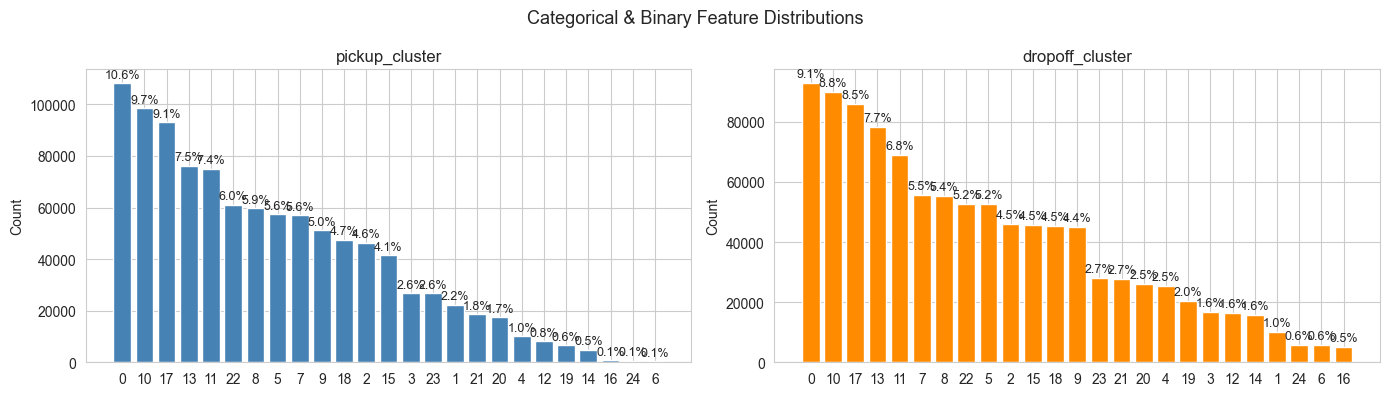

In [31]:
cl_cols = ["pickup_cluster","dropoff_cluster",]
cl_cols = [c for c in cl_cols if c in trn.columns]

fig, axes = plt.subplots(1, len(cl_cols), figsize=(14, 4))
if len(cl_cols) == 1:
    axes = [axes]

colors = ['steelblue', 'darkorange',]
for i, col in enumerate(cl_cols):
    counts = trn[col].value_counts()
    axes[i].bar(counts.index.astype(str), counts.values,color=colors[i % len(colors)], edgecolor='white')
    axes[i].set_title(col)
    axes[i].set_ylabel('Count')
    for j, v in enumerate(counts.values):
        axes[i].text(j, v + len(trn)*0.002,f'{v/len(trn)*100:.1f}%',ha='center', fontsize=9)

plt.suptitle('Categorical & Binary Feature Distributions', fontsize=13)
plt.tight_layout()
plt.show()


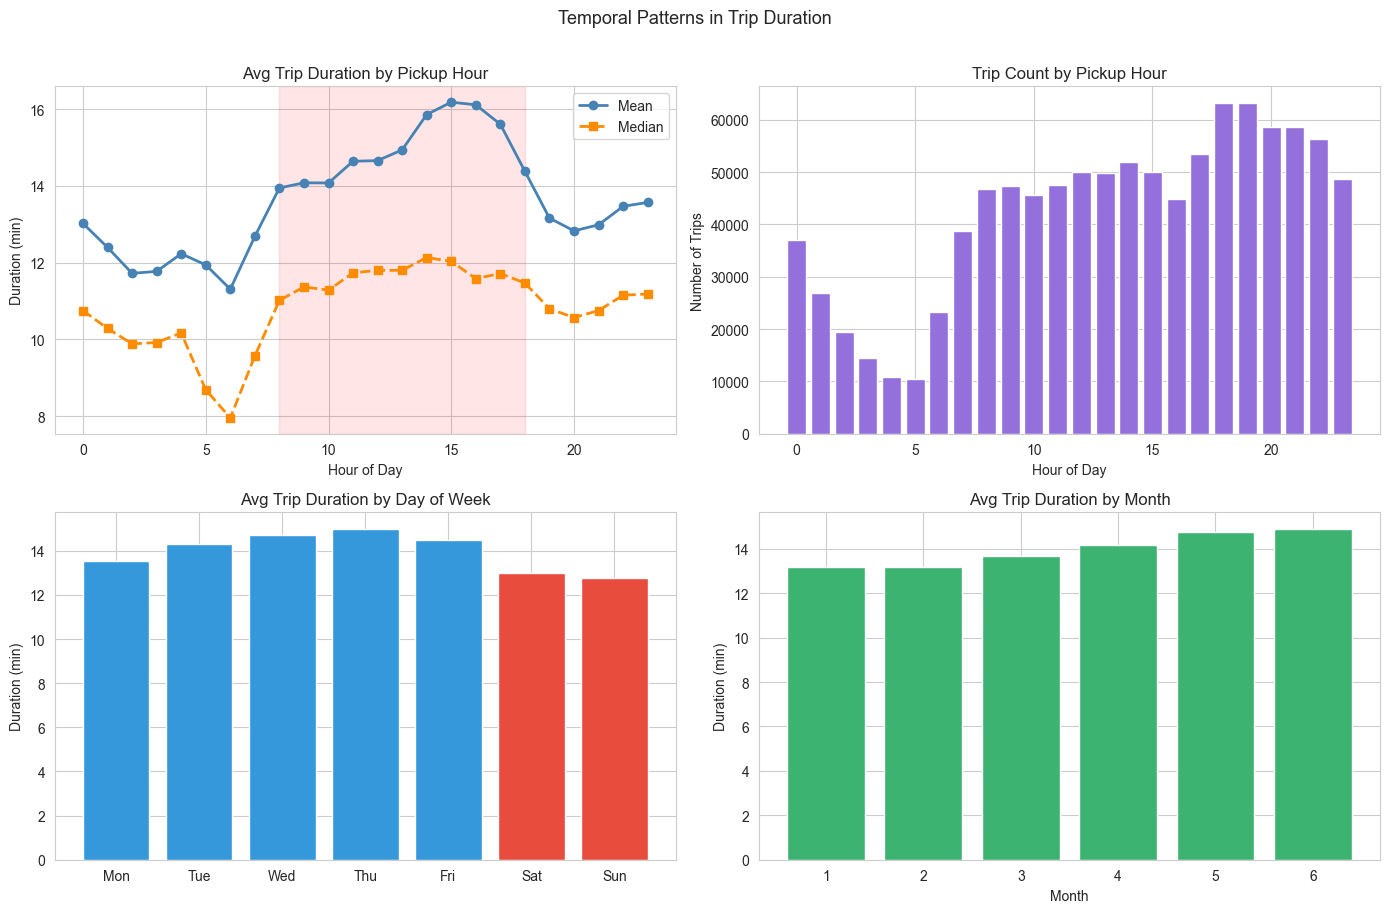

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Hour vs mean duration
hour_dur = trn.groupby('pickup_hour')['trip_duration_min'].agg(['mean','median'])
axes[0,0].plot(hour_dur.index, hour_dur['mean'], marker='o', color='steelblue',label='Mean', linewidth=2)
axes[0,0].plot(hour_dur.index, hour_dur['median'], marker='s', color='darkorange',linestyle='--', label='Median', linewidth=2)
axes[0,0].set_title('Avg Trip Duration by Pickup Hour')
axes[0,0].set_xlabel('Hour of Day')
axes[0,0].set_ylabel('Duration (min)')
axes[0,0].legend()
axes[0,0].axvspan(8, 18, alpha=0.1, color='red', label='AM Rush')


# Trip count by hour
hour_count = trn.groupby('pickup_hour').size()
axes[0,1].bar(hour_count.index, hour_count.values, color='mediumpurple', edgecolor='white')
axes[0,1].set_title('Trip Count by Pickup Hour')
axes[0,1].set_xlabel('Hour of Day')
axes[0,1].set_ylabel('Number of Trips')

# Day of week vs mean duration
dow_labels = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
dow_dur = trn.groupby('pickup_dayofweek')['trip_duration_min'].agg(['mean','median'])
axes[1,0].bar(dow_labels[:len(dow_dur)], dow_dur['mean'],color=['#3498db']*5 + ['#e74c3c']*2, edgecolor='white')
axes[1,0].set_title('Avg Trip Duration by Day of Week')
axes[1,0].set_ylabel('Duration (min)')

# Month vs mean duration
if 'pickup_month' in trn.columns:
    month_dur = trn.groupby('pickup_month')['trip_duration_min'].mean()
    axes[1,1].bar(month_dur.index, month_dur.values, color='mediumseagreen', edgecolor='white')
    axes[1,1].set_title('Avg Trip Duration by Month')
    axes[1,1].set_xlabel('Month')
    axes[1,1].set_ylabel('Duration (min)')

plt.suptitle('Temporal Patterns in Trip Duration', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

Temporal plots compare trip counts and durations by pickup hour, day and month. The rush-hour indicator is a hand-defined 08:00–18:00 inclusive window; traffic levels are not independently measured.

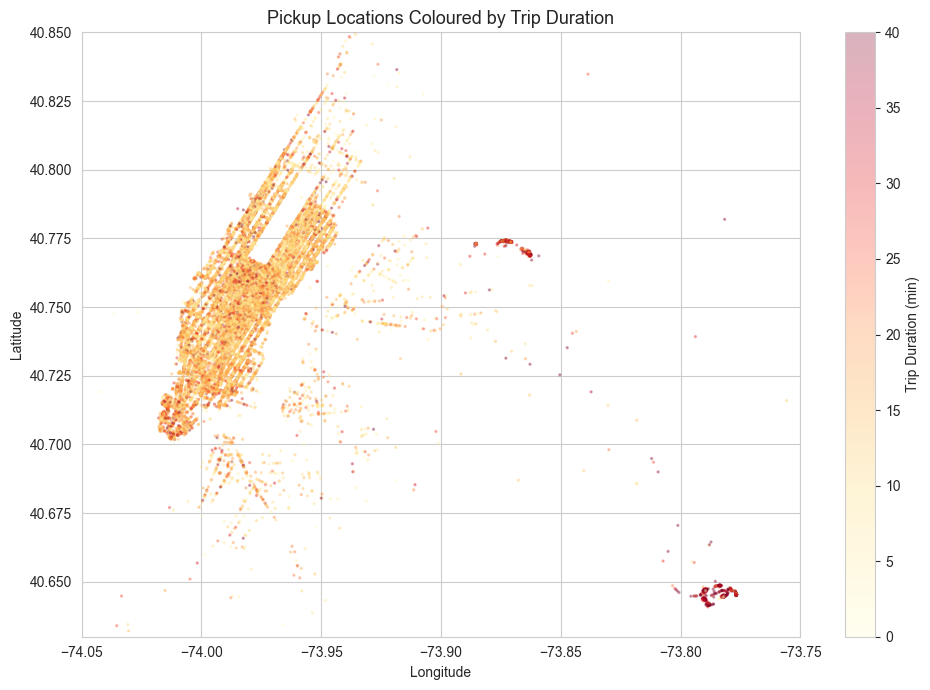

In [33]:
sample_geo = trn.sample(min(30_000, len(trn)), random_state=RS)

plt.figure(figsize=(10, 7))
sc = plt.scatter(sample_geo['pickup_longitude'],sample_geo['pickup_latitude'],c=sample_geo['trip_duration_min'],
                 cmap='YlOrRd', alpha=0.3, s=2,vmin=0, vmax=40)
plt.colorbar(sc, label='Trip Duration (min)')
plt.title('Pickup Locations Coloured by Trip Duration', fontsize=13)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.xlim(-74.05, -73.75)
plt.ylim(40.63, 40.85)
plt.tight_layout()
plt.show()

This geographic plot colours pickup locations by duration. It does not by itself establish that long trips are airport trips.

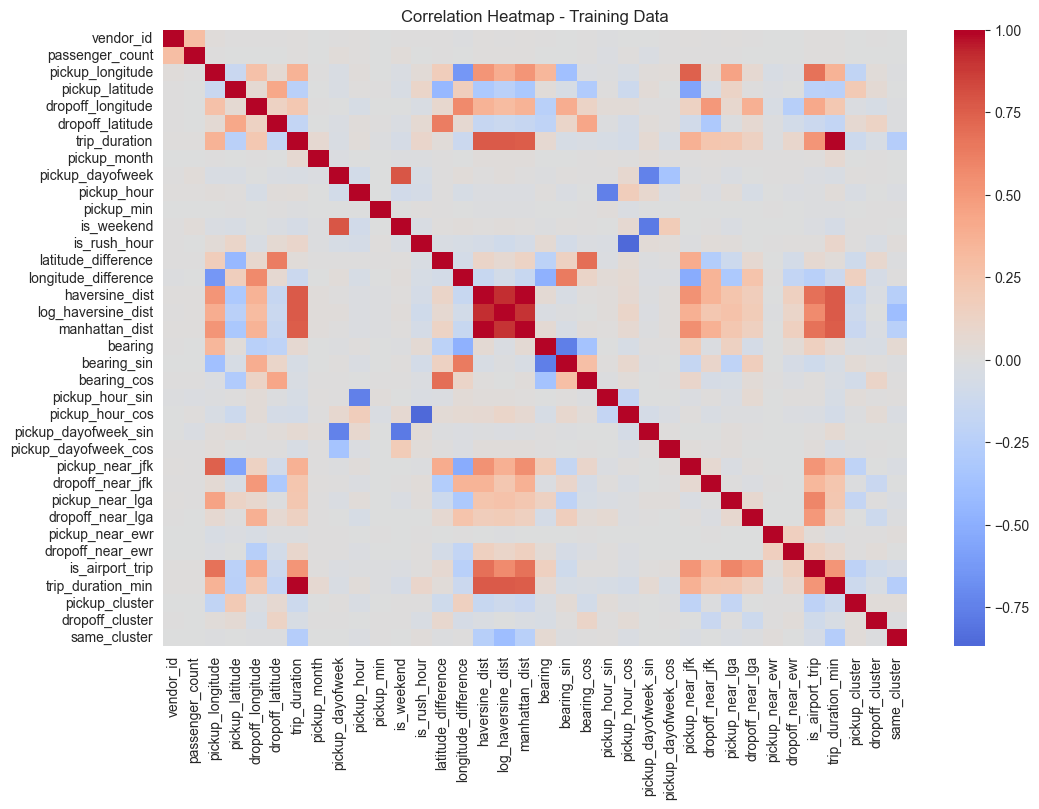

In [34]:
plt.figure(figsize=(12, 8))
corr = trn.corr(numeric_only=True)
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap - Training Data")
plt.show()

The heatmap describes numeric correlations in the training partition. Feature usefulness and model improvement require evaluation evidence beyond correlation.

## 9. Feature and Target Preparation

`trip_duration_min` is used only for exploration. Models target the original `trip_duration` in seconds and use the explicit feature lists below.

In [35]:
# Basic numeric features
base_num = [ 
    "passenger_count",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "pickup_month",
    "pickup_dayofweek",
    "pickup_hour",
    "pickup_min",
    "latitude_difference",
    "longitude_difference",
    "haversine_dist",
]

# categorical features
cat_f = [
    "vendor_id",
    "store_and_fwd_flag",
    "pickup_cluster",
    "dropoff_cluster",
]

# binary features
bin_f = [
    "is_weekend",
    "is_rush_hour",
    "pickup_near_jfk",
    "dropoff_near_jfk",
    "pickup_near_lga",
    "dropoff_near_lga",
    "pickup_near_ewr",
    "dropoff_near_ewr",
    "is_airport_trip",
    "same_cluster",
]

# all numerical features
num_f = base_num + [
    "log_haversine_dist",
    "manhattan_dist",
    "bearing",
    "bearing_sin",
    "bearing_cos",
    "pickup_hour_sin",
    "pickup_hour_cos",
    "pickup_dayofweek_sin",
    "pickup_dayofweek_cos",
] + bin_f


In [36]:
y_col = "trip_duration"
numeric_features = num_f
f_cols = cat_f + numeric_features   #All feature columns

In [37]:
X_tr = trn[f_cols]
y_tr = trn[y_col]
X_val = val[f_cols]
y_val = val[y_col]
X_te = tst[f_cols]
y_te = tst[y_col]

In [38]:
print("X_train:", X_tr.shape)
print("X_validation:", X_val.shape)
print("X_test:", X_te.shape)


X_train: (1017057, 35)
X_validation: (217941, 35)
X_test: (217941, 35)


## 10. Preprocessing and evaluation

Model pipelines impute, optionally scale numeric inputs and one-hot encode categories. These transformations are fitted through training model pipelines. The location clusters were already fitted on the full filtered pool before the split.

In [39]:
def make_one_hot_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


StandardScaler is defined inside the training-fitted numeric pipeline. This applies to model scaling, not the separate full-pool location clustering.

In [40]:
def make_preprocessor(num_f2, cat_f2, scale_num=True):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_num:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(steps=numeric_steps)

    categorical_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),("encoder", make_one_hot_encoder()),])

    return ColumnTransformer(transformers=[("num", numeric_pipeline, num_f2),("cat", categorical_pipeline, cat_f2),])

In [41]:
def make_pipe(model, num_f2=None, cat_f2=None, scale_num=True):
    if num_f2 is None:
        num_f2 = numeric_features
    if cat_f2 is None:
        cat_f2 = cat_f

    return Pipeline(steps=[("preprocessor", make_preprocessor(num_f2, cat_f2, scale_num)),("model", model),])

In [42]:
def pred_sec(model, X_data):
    y_pred = model.predict(X_data)
    return np.maximum(y_pred, 0)

In [43]:
def eval_model(m_name, model, X_data, y_true):
    y_pred = pred_sec(model, X_data)
    mse = mean_squared_error(y_true, y_pred)

    return {
    "Model": m_name,
    "MAE": mean_absolute_error(y_true, y_pred),
    "MSE": mse,
    "RMSE": np.sqrt(mse),
    "R2": r2_score(y_true, y_pred),
    }


## Feature-engineering scope

The final feature lists include distance, bearing, temporal, airport and spatial-cluster features. No matching executed ablation results are saved here, so the project does not establish that every retained feature improves the final score.

## 11. Initial Model Comparison

`Only three scikit-learn models are compared: Ridge Regression, Random Forest Regressor, and Hist Gradient Boosting Regressor.`


Training Ridge Regression...
Training Random Forest Regressor...
Training Hist Gradient Boosting Regressor...


,Model,MAE,MSE,RMSE,R2
2,Hist Gradient Boosting Regressor,186.552992,90760.705829,301.265175,0.790802
1,Random Forest Regressor,208.743491,107110.785957,327.277842,0.753116
0,Ridge Regression,239.586149,135078.075959,367.529694,0.688653


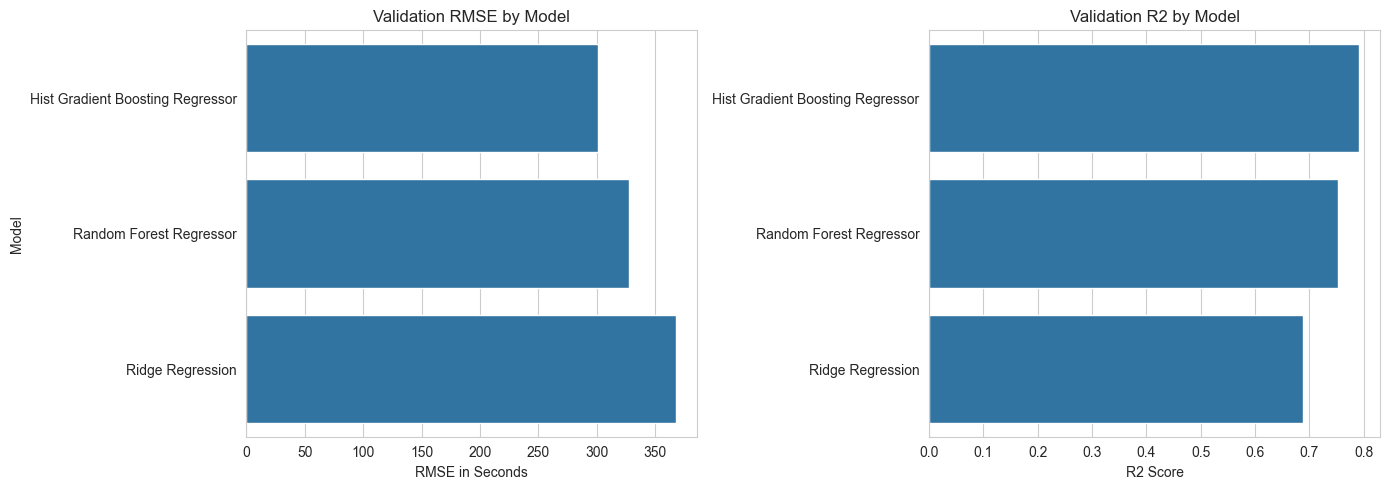

In [44]:
pipes = {
    "Ridge Regression": make_pipe(Ridge(alpha=0.1)),

    "Random Forest Regressor": make_pipe(
        RandomForestRegressor(n_estimators=100,max_depth=10,min_samples_leaf=5,random_state=RS,n_jobs=-1,)),

    "Hist Gradient Boosting Regressor": make_pipe(
        HistGradientBoostingRegressor(max_iter=200,learning_rate=0.08,max_leaf_nodes=31,random_state=RS,)),}

# Store validation metrics for model comparison.
val_rows = []

for m_name, model in pipes.items():
    print(f"Training {m_name}...")
    model.fit(X_tr, y_tr)
    val_rows.append(eval_model(m_name, model, X_val, y_val))

val_df = pd.DataFrame(val_rows).sort_values("RMSE")
display(val_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=val_df, x="RMSE", y="Model", ax=axes[0])
axes[0].set_title("Validation RMSE by Model")
axes[0].set_xlabel("RMSE in Seconds")
sns.barplot(data=val_df, x="R2", y="Model", ax=axes[1])
axes[1].set_title("Validation R2 by Model")
axes[1].set_xlabel("R2 Score")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()


## 12. Retained hyperparameter configurations

Validation RMSE compares the retained Random Forest and HistGradientBoosting configurations. Each final parameter grid contains one combination. The code does not rerun a broad hyperparameter search.

### Experiment history

The original project describes broader prior searches, but this notebook retains only one selected configuration per tuned estimator. The source has no saved search outputs establishing the complete search scope or results. The retained parameter values are implementation facts, not reproduced optimality evidence.

In [45]:
def tune_model_on_validation(m_name, base_pipe, grid):
    rows = []
    best_pipe = None
    best_rmse = np.inf

    for params in ParameterGrid(grid):
        model = clone(base_pipe)
        model.set_params(**params)
        print(f"Training {m_name} with parameters: {params}")
        model.fit(X_tr, y_tr)

        scores = eval_model(m_name, model, X_val, y_val)
        print(f"Score: {scores}")
        scores["Parameters"] = params
        rows.append(scores)

        if scores["RMSE"] < best_rmse:
            best_rmse = scores["RMSE"]
            best_pipe = model

    return pd.DataFrame(rows).sort_values("RMSE"), best_pipe

rf_grid = {
    "model__n_estimators": [300],
    "model__max_depth": [30],
    "model__min_samples_leaf": [20],
    "model__max_features": ["sqrt"]
}

hgb_grid = {
    "model__max_iter": [600],
    "model__learning_rate": [0.10],
    "model__max_leaf_nodes": [191],
    "model__l2_regularization": [0.03],
    "model__min_samples_leaf": [50],
}

rf_res, rf_best = tune_model_on_validation(
    "Random Forest Regressor",
    pipes["Random Forest Regressor"],
    rf_grid,
)
display(rf_res)

hgb_res, hgb_best = tune_model_on_validation(
    "Hist Gradient Boosting Regressor",
    pipes["Hist Gradient Boosting Regressor"],
    hgb_grid,
)
display(hgb_res)

best_res = pd.concat(
    [rf_res.head(1), hgb_res.head(1)],
    ignore_index=True,
).sort_values("RMSE")
display(best_res)


Training Random Forest Regressor with parameters: {'model__max_depth': 30, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 20, 'model__n_estimators': 300}
Score: {'Model': 'Random Forest Regressor', 'MAE': 187.25328815758766, 'MSE': 91982.14761690196, 'RMSE': np.float64(303.285587552231), 'R2': 0.7879864802771048}


,Model,MAE,MSE,RMSE,R2,Parameters
0,Random Forest Regressor,187.253288,91982.147617,303.285588,0.787986,"{'model__max_depth': 30, 'model__max_features'..."


Training Hist Gradient Boosting Regressor with parameters: {'model__l2_regularization': 0.03, 'model__learning_rate': 0.1, 'model__max_iter': 600, 'model__max_leaf_nodes': 191, 'model__min_samples_leaf': 50}
Score: {'Model': 'Hist Gradient Boosting Regressor', 'MAE': 172.98767882716982, 'MSE': 81785.98901689229, 'RMSE': np.float64(285.9824977457402), 'R2': 0.8114880349640461}


,Model,MAE,MSE,RMSE,R2,Parameters
0,Hist Gradient Boosting Regressor,172.987679,81785.989017,285.982498,0.811488,"{'model__l2_regularization': 0.03, 'model__lea..."


,Model,MAE,MSE,RMSE,R2,Parameters
1,Hist Gradient Boosting Regressor,172.987679,81785.989017,285.982498,0.811488,"{'model__l2_regularization': 0.03, 'model__lea..."
0,Random Forest Regressor,187.253288,91982.147617,303.285588,0.787986,"{'model__max_depth': 30, 'model__max_features'..."


In [46]:
# Select the best tuned model based on validation RMSE.

best_name = best_res.iloc[0]["Model"]
best_model = rf_best if best_name == "RFR" else hgb_best
print(best_name)

Hist Gradient Boosting Regressor


## 13. Internal test evaluation

The code defines evaluation in seconds and test residual plots. No saved metric tables or prediction outputs are present. The final selection condition compares `best_name` with `RFR`, while result names use `Random Forest Regressor`; with the current labels it selects `hgb_best`, even when Random Forest has lower validation RMSE. The displayed name can therefore differ from the evaluated estimator.

,Model,MAE,MSE,RMSE,R2
0,Hist Gradient Boosting Regressor,172.978503,84567.408088,290.804759,0.805769


,actual_trip_duration,predicted_trip_duration,error,absolute_error
1155540,1108,1170.892947,-62.892947,62.892947
747788,1075,975.861750,99.138250,99.138250
1195881,1301,1235.842839,65.157161,65.157161
1029248,631,934.498421,-303.498421,303.498421
373143,978,1176.436427,-198.436427,198.436427


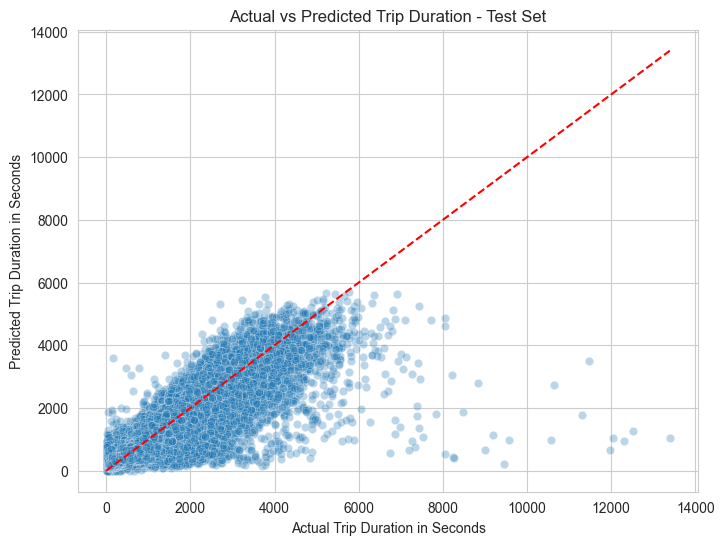

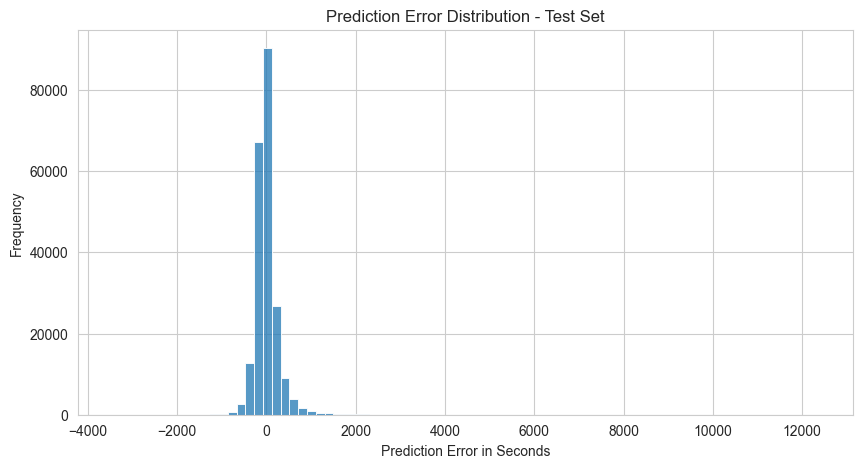

In [47]:
# Evaluate the selected final model once on the internal test set and visualize prediction errors.

# Evaluate the final selected model on the untouched internal test set.
te_scores = eval_model(best_name, best_model, X_te, y_te)
te_df = pd.DataFrame([te_scores])
display(te_df)

# Generate test-set predictions in seconds for residual and error analysis.
y_hat = pred_sec(best_model, X_te)
err_df = pd.DataFrame({
    "actual_trip_duration": y_te,
    "predicted_trip_duration": y_hat,
    "error": y_te - y_hat,
    "absolute_error": np.abs(y_te - y_hat),
})
display(err_df.head())

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=err_df["actual_trip_duration"],
    y=err_df["predicted_trip_duration"],
    alpha=0.3,
)
max_duration = err_df["actual_trip_duration"].max()
plt.plot([0, max_duration], [0, max_duration], color="red", linestyle="--")
plt.title("Actual vs Predicted Trip Duration - Test Set")
plt.xlabel("Actual Trip Duration in Seconds")
plt.ylabel("Predicted Trip Duration in Seconds")
plt.show()

plt.figure(figsize=(10, 5))
sns.histplot(err_df["error"], bins=80)
plt.title("Prediction Error Distribution - Test Set")
plt.xlabel("Prediction Error in Seconds")
plt.ylabel("Frequency")
plt.show()


## 14. Error Analysis by Duration Group

Aggregate metrics can hide weak performance on rare trip types. Grouping by duration shows whether the model behaves differently for short, medium, and long trips.


,duration_group,trips,mean_actual_duration,mean_predicted_duration,mean_absolute_error,median_absolute_error
0,0-5 min,32782,207.778171,301.410779,102.157663,81.741035
1,5-10 min,64633,447.156685,503.597456,105.450439,84.023722
2,10-20 min,76345,852.716353,862.682518,157.548960,124.976686
3,20-30 min,27663,1448.824495,1369.238184,254.946702,201.490973
4,30-60 min,15000,2340.990000,2107.293725,444.723762,338.848769
5,60+ min,1518,4438.314888,3403.483775,1174.621018,798.355662


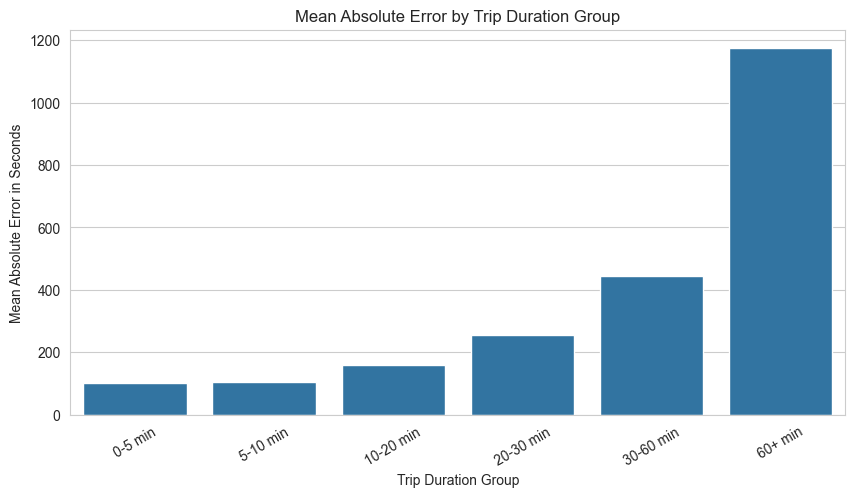

In [48]:
# Break down test errors by trip-duration group to see where the model performs well or poorly.

err_df["duration_group"] = pd.cut(
    err_df["actual_trip_duration"],
    bins=[0, 300, 600, 1200, 1800, 3600, np.inf],
    labels=["0-5 min", "5-10 min", "10-20 min", "20-30 min", "30-60 min", "60+ min"],
)

dur_err = (
    err_df
    .groupby("duration_group")
    .agg(
        trips=("actual_trip_duration", "count"),
        mean_actual_duration=("actual_trip_duration", "mean"),
        mean_predicted_duration=("predicted_trip_duration", "mean"),
        mean_absolute_error=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median"),
    )
    .reset_index()
)
display(dur_err)

plt.figure(figsize=(10, 5))
sns.barplot(data=dur_err, x="duration_group", y="mean_absolute_error")
plt.title("Mean Absolute Error by Trip Duration Group")
plt.xlabel("Trip Duration Group")
plt.ylabel("Mean Absolute Error in Seconds")
plt.xticks(rotation=30)
plt.show()


## 15. Conclusion and evidence status

The notebook implements spatial/time feature engineering, scoped filtering, model pipelines, comparison of Ridge, Random Forest and HistGradientBoosting, and internal-test residual analysis. This source copy has no saved execution outputs.

The original conclusion reports HGB MAE 172.98 seconds, MSE 84,567.41 seconds², RMSE 290.80 seconds and R² 0.8058. These values are preserved as **unverified narrative claims**; matching evaluation outputs are absent and the values have not been independently reproduced. They are not a current performance guarantee or a freshly verified portfolio result.

Current limitations include full-pool clustering before the split, the winner-name condition, a random rather than chronological holdout, scope-limiting filters, and no measured traffic/weather/route context. Model superiority, feature contributions and real-world impact are not established by this unexecuted source. See [limitations](docs/EVIDENCE.md).

## 17. References

- https://www.kaggle.com/competitions/nyc-taxi-trip-duration/data
- https://scikit-learn.org/stable/
- https://pandas.pydata.org/docs/
- https://numpy.org/doc/
- https://matplotlib.org/stable/
- https://seaborn.pydata.org/